## Lab 2 What Did the Campaign Deliver?
Name: Korinnyi Zakhar

Group: KM-43

### Setup

In [1]:
import kagglehub
import pandas as pd
import matplotlib.pyplot as plt

DATA = kagglehub.dataset_download("shkarupylomaxim/adtech-lab1-tv-panel/versions/3")

programs = pd.read_parquet(f"{DATA}/programs.parquet")
viewings = pd.read_parquet(f"{DATA}/viewings.parquet")
daily_weights = pd.read_parquet(f"{DATA}/daily_weights.parquet")
viewer_attributes = pd.read_parquet(f"{DATA}/viewer_attributes.parquet")
attributes = pd.read_parquet(f"{DATA}/attributes.parquet")
commercials = pd.read_parquet(f"{DATA}/commercials.parquet")
rate_card = pd.read_parquet(f"{DATA}/rate_card.parquet")

100%|██████████| 8.00M/8.00M [00:00<00:00, 78.3MB/s]

Extracting files...


### Task 1.1 - Size

In [2]:
print("Spots:", commercials['ad_airing_id'].nunique())
print("Pods:", commercials['pod_id'].nunique())
print("Brands:", commercials['brand'].nunique())
print("Categories:", commercials['category'].nunique())

brand_a_spots = commercials[commercials['brand'] == 'BRAND_A']
print("BRAND_A spots:", len(brand_a_spots))

# table: BRAND_A spots by network
print(brand_a_spots['network_code'].value_counts().to_string())

Spots: 167720
Pods: 22359
Brands: 95
Categories: 14
BRAND_A spots: 300
network_code
FNC      40
HGTV     39
FX       38
HIST     37
BRAVO    33
FOOD     33
ABC      29
CBS      22
NBC      16
FOX      13


### Task 1.2 Ad load

In [3]:
# calculate average ad load per active hour
commercials['clock_hour'] = commercials['start_ts'].dt.floor('h')
hourly_load = commercials.groupby(['network_code', 'clock_hour'])['length_sec'].sum()
hourly_load_min = hourly_load / 60.0
ad_load_avg = hourly_load_min.groupby('network_code').mean().sort_values(ascending=False)

# table: ad minutes per hour by network
print(ad_load_avg.round(1).to_string())

print("\nHeaviest ad load:", ad_load_avg.idxmax())

network_code
FNC      15.6
BRAVO    13.4
HGTV     13.3
HIST     13.2
FOOD     13.1
FX       12.9
CBS      12.1
ABC      11.8
NBC      11.8
FOX      11.8

Heaviest ad load: FNC


**Answer:** Broadcast networks (ABC, CBS, NBC, FOX) are made up of local member stations (affiliates). The schedule includes full hours that are entirely dedicated to local programming (such as local news), during which all advertising inventory is sold locally (local avails). Since our dataset contains only national advertising, we see zero national commercials during these hours.

### Task 1.3 Price everything

In [4]:
# get program names
spots = commercials.merge(programs[['telecast_id', 'program_name']], on='telecast_id', how='left')

# calculate broadcast day offset
spots['bc_dt'] = spots['start_ts'] - pd.Timedelta(hours=6)
spots['bc_weekday'] = spots['bc_dt'].dt.dayofweek
spots['bc_mins'] = spots['bc_dt'].dt.hour * 60 + spots['bc_dt'].dt.minute

# split rate card into program and time prices
rc_prog = rate_card[rate_card['program_name'].notna() & (rate_card['program_name'] != '')]
rc_time = rate_card[rate_card['program_name'].isna() | (rate_card['program_name'] == '')].copy()

def parse_mins(t_str):
    h, m = map(int, t_str.split(':'))
    return h * 60 + m - 360

rc_time['start_min'] = rc_time['start_time'].apply(parse_mins)
rc_time['end_min'] = rc_time['end_time'].apply(parse_mins)

rc_time = rc_time.explode('weekdays')

# match sports and special programs first
spots_prog = spots.merge(rc_prog[['network_code', 'program_name', 'daypart', 'cost_30s_usd']],
                         on=['network_code', 'program_name'], how='inner')
spots_prog['is_prog'] = True

# match the rest
unmatched = spots[~spots['ad_airing_id'].isin(spots_prog['ad_airing_id'])]
spots_time = unmatched.merge(rc_time[['network_code', 'weekdays', 'daypart', 'cost_30s_usd', 'start_min', 'end_min']],
                             left_on=['network_code', 'bc_weekday'], right_on=['network_code', 'weekdays'], how='inner')
spots_time = spots_time[(spots_time['bc_mins'] >= spots_time['start_min']) & (spots_time['bc_mins'] < spots_time['end_min'])]
spots_time['is_prog'] = False

# adjust price based on spot length
priced_spots = pd.concat([spots_prog, spots_time], ignore_index=True)
priced_spots['cost'] = priced_spots['cost_30s_usd'] * (priced_spots['length_sec'] / 30.0)

unpriced_count = len(spots) - len(priced_spots)
print("Spots without a price:", unpriced_count)

commercials = priced_spots

# table: rate-card value by network (USD M) and share from program rows
net_summary = commercials.groupby('network_code').agg(
    total_value=('cost', 'sum'),
    prog_cost=('cost', lambda x: x[commercials.loc[x.index, 'is_prog']].sum())
)
net_summary['Total Value (USD M)'] = net_summary['total_value'] / 1_000_000
net_summary['Program Share'] = net_summary['prog_cost'] / net_summary['total_value']

res_table = net_summary[['Total Value (USD M)', 'Program Share']].sort_values('Total Value (USD M)', ascending=False)
print("\nRate-card value by network:")
print(res_table.to_string(formatters={'Total Value (USD M)': '{:.2f}'.format, 'Program Share': '{:.3f}'.format}))

Spots without a price: 0

Rate-card value by network:
             Total Value (USD M) Program Share
network_code                                  
CBS                       818.78         0.230
NBC                       724.32         0.342
ABC                       708.79         0.432
FOX                       696.17         0.835
FNC                       315.85         0.000
HGTV                       58.10         0.000
FX                         42.51         0.000
FOOD                       42.15         0.000
HIST                       40.09         0.000
BRAVO                      25.31         0.000


### Task 2.1 - Delivery

In [5]:
# get BRAND_A spots and broadcast date
brand_ads = commercials[commercials['brand'] == 'BRAND_A'].copy()
brand_ads['bc_date'] = (brand_ads['start_ts'] - pd.Timedelta(hours=6)).dt.date

# get valid persons and ages
person_views = viewings[viewings['resp_type'].isin(['R', 'L'])].copy()
ages = viewer_attributes[viewer_attributes['attr_id'] == 300][['respondent_id', 'value']].rename(columns={'value': 'age'})

# match spots with viewers
view_records = []
for _, spot in brand_ads.iterrows():
    mask = (person_views['network_code'] == spot['network_code']) & \
           (person_views['start_ts'] <= spot['start_ts']) & \
           (person_views['end_ts'] > spot['start_ts'])
    viewers = person_views[mask]['respondent_id'].unique()
    for v in viewers:
        view_records.append({'ad_airing_id': spot['ad_airing_id'], 'respondent_id': v, 'bc_date': spot['bc_date']})

ad_views = pd.DataFrame(view_records)
ad_views = ad_views.merge(ages, on='respondent_id', how='left')

# merge daily weights and set target flag
person_weights = daily_weights[daily_weights['resp_type'].isin(['R', 'L'])]
ad_views = ad_views.merge(person_weights[['respondent_id', 'broadcast_date', 'weight']],
                          left_on=['respondent_id', 'bc_date'],
                          right_on=['respondent_id', 'broadcast_date'], how='inner')
ad_views['is_target'] = (ad_views['age'] >= 18) & (ad_views['age'] <= 49)

# calculate daily total weights for denominators
daily_demo = person_weights.merge(ages, on='respondent_id', how='left')
daily_demo['is_target'] = (daily_demo['age'] >= 18) & (daily_demo['age'] <= 49)

daily_totals = daily_demo.groupby('broadcast_date').agg(
    base_p2=('weight', 'sum'),
    base_target=('weight', lambda x: x[daily_demo.loc[x.index, 'is_target']].sum())
).reset_index()

# calc daily denominators
spot_metrics = ad_views.groupby(['ad_airing_id', 'bc_date']).agg(
    imp_p2=('weight', 'sum'),
    imp_target=('weight', lambda x: x[ad_views.loc[x.index, 'is_target']].sum())
).reset_index()

# calc ratings
spot_metrics = spot_metrics.merge(daily_totals, left_on='bc_date', right_on='broadcast_date', how='left')
spot_metrics['rating_p2'] = (spot_metrics['imp_p2'] / spot_metrics['base_p2']) * 100
spot_metrics['rating_target'] = (spot_metrics['imp_target'] / spot_metrics['base_target']) * 100

# campaign totals
grps_p2 = spot_metrics['rating_p2'].sum()
grps_target = spot_metrics['rating_target'].sum()
imps_p2 = spot_metrics['imp_p2'].sum() / 1_000_000
imps_target = spot_metrics['imp_target'].sum() / 1_000_000

# calc universe and reach
monthly = person_weights.groupby('respondent_id')['weight'].mean().reset_index().rename(columns={'weight': 'monthly_weight'})
monthly = monthly.merge(ages, on='respondent_id', how='left')
monthly['is_target'] = (monthly['age'] >= 18) & (monthly['age'] <= 49)

universe_p2 = monthly['monthly_weight'].sum()
universe_target = monthly[monthly['is_target']]['monthly_weight'].sum()

reached_p2 = ad_views['respondent_id'].unique()
reached_target = ad_views[ad_views['is_target']]['respondent_id'].unique()

reach_p2 = monthly[monthly['respondent_id'].isin(reached_p2)]['monthly_weight'].sum() / universe_p2 * 100
reach_target = monthly[monthly['respondent_id'].isin(reached_target)]['monthly_weight'].sum() / universe_target * 100

freq_p2 = grps_p2 / reach_p2
freq_target = grps_target / reach_target

print(f"P2+ impressions (M): {imps_p2:.1f}")
print(f"P2+ GRPs: {grps_p2:.1f}")
print(f"P2+ reach (%): {reach_p2:.1f}")
print(f"P2+ average frequency: {freq_p2:.1f}")
print(f"A18-49 impressions (M): {imps_target:.1f}")
print(f"A18-49 GRPs: {grps_target:.1f}")
print(f"A18-49 reach (%): {reach_target:.1f}")
print(f"A18-49 average frequency: {freq_target:.1f}")

P2+ impressions (M): 418.8
P2+ GRPs: 132.0
P2+ reach (%): 43.5
P2+ average frequency: 3.0
A18-49 impressions (M): 81.1
A18-49 GRPs: 60.4
A18-49 reach (%): 30.5
A18-49 average frequency: 2.0


### Task 2.2 Frequency distribution

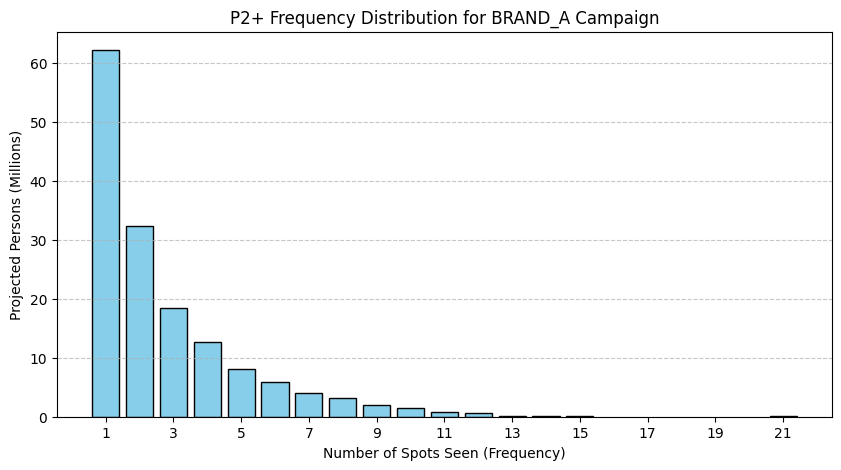

Share of impressions at 5+ exposures: 0.443


In [6]:
# count spots per person
viewer_freq = ad_views.groupby('respondent_id')['ad_airing_id'].count().reset_index()
viewer_freq.columns = ['respondent_id', 'frequency']

# apply monthly weights
viewer_freq = viewer_freq.merge(monthly[['respondent_id', 'monthly_weight']], on='respondent_id', how='left')

# calc frequency distribution
freq_dist = viewer_freq.groupby('frequency')['monthly_weight'].sum() / 1_000_000

# plot: projected persons (M) by number of spots seen
plt.figure(figsize=(10, 5))
plt.bar(freq_dist.index, freq_dist.values, color='skyblue', edgecolor='black')
plt.title('P2+ Frequency Distribution for BRAND_A Campaign')
plt.xlabel('Number of Spots Seen (Frequency)')
plt.ylabel('Projected Persons (Millions)')
plt.xticks(range(1, int(viewer_freq['frequency'].max()) + 1, 2))
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

# calc share of 5+ exposures
viewer_freq['impressions'] = viewer_freq['frequency'] * viewer_freq['monthly_weight']
total_campaign_imps = viewer_freq['impressions'].sum()
imps_5plus = viewer_freq[viewer_freq['frequency'] >= 5]['impressions'].sum()

share_5plus = imps_5plus / total_campaign_imps
print(f"Share of impressions at 5+ exposures: {share_5plus:.3f}")

**Answer:** No, the average rate (3.0) doesn't give an honest picture. As the graph shows, the big part of people saw the ad only 1 or 2 times (over 60 million people saw it once, and over 30 million saw it twice). However, a huge proportion of all ad impressions (44.3%) came from a small group of viewers who saw the ad 5 or more times (some as many as 21 times). This long “tail” of loyal viewers artificially raises the arithmetic mean, failing to represent the experience of the typical viewer.


### Task 2.3 On target?

In [7]:
# calculate target impression share
target_share = imps_target / imps_p2
print(f"Share of impressions on A18-49: {target_share:.3f}")

Share of impressions on A18-49: 0.194


**Answer:** The campaign seriously failed to reach its target audience(under-delivered). Although the A18-49 demographic accounts for 42% of the population, it received only 19.4% of the views. This is directly explained by the choice of networks for placement: the largest number of ads (from Task 1.1) aired on FNC (40), HGTV (39), and HIST (37). From our previous lab study, we know that channels such as FNC have the oldest audience (leading in the M55+ and W55+ groups). Therefore, the budget was spent on viewers who are not part of the brand’s target audience.

### Task 3.1 - Cost

In [8]:
total_cost = brand_ads['cost'].sum()

# CPM
cpm_p2 = total_cost / (imps_p2 * 1000)
cpm_target = total_cost / (imps_target * 1000)

# CPP
cpp_p2 = total_cost / grps_p2
cpp_target = total_cost / grps_target

print(f"Campaign cost (USD): {total_cost:.0f}")
print(f"P2+ CPM (USD): {cpm_p2:.2f}")
print(f"P2+ CPP (USD): {cpp_p2:.0f}")
print(f"A18-49 CPM (USD): {cpm_target:.2f}")
print(f"A18-49 CPP (USD): {cpp_target:.0f}")

Campaign cost (USD): 7420270
P2+ CPM (USD): 17.72
P2+ CPP (USD): 56221
A18-49 CPM (USD): 91.53
A18-49 CPP (USD): 122836


### Task 3.2 By network

In [9]:
# calc costs per network
net_costs = brand_ads.groupby('network_code').agg(
    spots=('ad_airing_id', 'count'),
    cost=('cost', 'sum')
).reset_index()

# calc impressions per network
net_imps = spot_metrics.merge(brand_ads[['ad_airing_id', 'network_code']], on='ad_airing_id', how='left')
net_imps_agg = net_imps.groupby('network_code').agg(
    imp_p2=('imp_p2', 'sum'),
    imp_target=('imp_target', 'sum')
).reset_index()

# merge and calc CPM
net_stats = net_costs.merge(net_imps_agg, on='network_code', how='left')
net_stats['imp_p2_m'] = net_stats['imp_p2'] / 1_000_000
net_stats['imp_target_m'] = net_stats['imp_target'] / 1_000_000

net_stats['P2+ CPM'] = net_stats['cost'] / (net_stats['imp_p2_m'] * 1000)
net_stats['A18-49 CPM'] = net_stats['cost'] / (net_stats['imp_target_m'] * 1000)

# table: spots, cost, impressions, P2+ CPM and A18-49 CPM by network
res_table = net_stats[['network_code', 'spots', 'cost', 'imp_p2_m', 'P2+ CPM', 'A18-49 CPM']].sort_values('cost', ascending=False)
res_table = res_table.rename(columns={'cost': 'Cost (USD)', 'imp_p2_m': 'P2+ Imps (M)'})
print(res_table.to_string(formatters={'Cost (USD)': '{:.0f}'.format, 'P2+ Imps (M)': '{:.1f}'.format, 'P2+ CPM': '{:.2f}'.format, 'A18-49 CPM': '{:.2f}'.format}, index=False))

network_code  spots Cost (USD) P2+ Imps (M) P2+ CPM A18-49 CPM
         FOX     13    2434700         76.3   31.93     132.03
         ABC     29    1625700         94.2   17.26      95.69
         CBS     22    1488700         89.0   16.73     108.72
         NBC     16     796800         41.4   19.23     101.72
         FNC     40     526300         57.8    9.11     193.70
        HGTV     39     230000         24.7    9.33      30.45
        FOOD     33      96620          9.5   10.19      32.29
          FX     38      92200          8.5   10.82      16.61
        HIST     37      79640         12.3    6.46      32.05
       BRAVO     33      49610          5.1    9.76      17.61


**Answer:** The largest part of the budget (nearly \$6.34 million out of \$7.4 million) was spent on mainstream broadcast networks (FOX, ABC, CBS, NBC). FOX alone accounted for over $2.4 million for 13 advertisements. However, the most cost-effective way to reach the target audience (A18-49) turned out to be smaller cable networks: FX (CPM 16.61) and BRAVO (CPM 17.61). Major networks, especially the news network FNC (CPM 193.70), proved to be extremely costly and ineffective for this age group.

### Task 3.3 - Guarantee

In [10]:
guarantee_grps = 150.0
guarantee_met = grps_p2 >= guarantee_grps
make_goods_owed = max(0, guarantee_grps - grps_p2)
make_goods_value = make_goods_owed * cpp_p2

# True / False
print(f"Guarantee met: {guarantee_met}")
print(f"Make-good GRPs owed: {make_goods_owed:.1f}")
print(f"Value of make-goods (USD): {make_goods_value:.0f}")

Guarantee met: False
Make-good GRPs owed: 18.0
Value of make-goods (USD): 1012869


### Task 4 Do networks add up?

In [11]:
# prep data and split by network size
ad_views_net = ad_views.merge(brand_ads[['ad_airing_id', 'network_code']], on='ad_airing_id', how='left')

big_nets = ['CBS', 'NBC', 'ABC', 'FOX', 'FNC']
small_nets = ['FX', 'BRAVO', 'HGTV', 'FOOD', 'HIST']

views_big = ad_views_net[ad_views_net['network_code'].isin(big_nets)]
views_small = ad_views_net[ad_views_net['network_code'].isin(small_nets)]

reach_ids_big = views_big['respondent_id'].unique()
reach_ids_small = views_small['respondent_id'].unique()

# calc reach metrics
reach_big_pct = monthly[monthly['respondent_id'].isin(reach_ids_big)]['monthly_weight'].sum() / universe_p2 * 100
reach_small_pct = monthly[monthly['respondent_id'].isin(reach_ids_small)]['monthly_weight'].sum() / universe_p2 * 100
reach_whole_pct = reach_p2  # from Task 2.1

# calc overlap and added reach
overlap_ids = set(reach_ids_big).intersection(set(reach_ids_small))
overlap_pct = monthly[monthly['respondent_id'].isin(overlap_ids)]['monthly_weight'].sum() / universe_p2 * 100

overlap_indep = (reach_big_pct / 100) * (reach_small_pct / 100) * 100

added_reach = reach_whole_pct - reach_big_pct

# calc costs
cost_big = brand_ads[brand_ads['network_code'].isin(big_nets)]['cost'].sum()
cost_small = brand_ads[brand_ads['network_code'].isin(small_nets)]['cost'].sum()

cost_per_pt_big = cost_big / reach_big_pct
cost_per_added_pt_small = cost_small / added_reach if added_reach > 0 else 0

print(f"Reach, big networks (%): {reach_big_pct:.1f}")
print(f"Reach, small networks (%): {reach_small_pct:.1f}")
print(f"Reach, whole campaign (%): {reach_whole_pct:.1f}")
print(f"Overlap (%): {overlap_pct:.1f}")
print(f"Overlap if independent (%): {overlap_indep:.1f}")
print(f"Reach added by small networks (points): {added_reach:.1f}")
print(f"Cost per added reach point, small (USD): {cost_per_added_pt_small:.0f}")
print(f"Cost per reach point, big (USD): {cost_per_pt_big:.0f}")

Reach, big networks (%): 39.8
Reach, small networks (%): 12.4
Reach, whole campaign (%): 43.5
Overlap (%): 8.7
Overlap if independent (%): 4.9
Reach added by small networks (points): 3.7
Cost per added reach point, small (USD): 148706
Cost per reach point, big (USD): 172456


**Answer:** The total reach (43.5%) is less than the sum of the reaches of both groups (52.2%), because some people saw the ad on both large and small networks (audience overlap), but they are counted only once in the total figure. The actual overlap (8.7%) turned out to be much greater than the theoretical independent overlap (4.9%). This means that viewers of small networks watch big channels more often than the average viewer (these are so-called “heavy” viewers, who generally spend a lot of time watching TV). The money spent on small networks was used effectively, because they added 3.7 points of unique reach, and the cost per added point (\$148,706) was lower than the cost per base point on large networks (\$172,456).

### Task 5 How sure are we?

In [12]:
# calc median panelists per spot
viewers_per_ad = ad_views.groupby('ad_airing_id')['respondent_id'].count().reset_index(name='panelists')
all_ads = brand_ads[['ad_airing_id', 'network_code', 'bc_date']].merge(viewers_per_ad, on='ad_airing_id', how='left')
all_ads['panelists'] = all_ads['panelists'].fillna(0)
median_viewers = all_ads.groupby('network_code')['panelists'].median()

# calc standard errors
daily_people = person_weights.groupby('broadcast_date')['respondent_id'].nunique().reset_index(name='sample_size')
ad_errors = spot_metrics[['ad_airing_id', 'bc_date', 'rating_p2']].merge(daily_people, left_on='bc_date', right_on='broadcast_date', how='left')
ad_errors = ad_errors.merge(brand_ads[['ad_airing_id', 'network_code']], on='ad_airing_id', how='left')

rating_fraction = ad_errors['rating_p2'] / 100.0
ad_errors['standard_error'] = ((rating_fraction * (1 - rating_fraction)) / ad_errors['sample_size']) ** 0.5 * 100
ad_errors['relative_error'] = ad_errors['standard_error'] / ad_errors['rating_p2']

error_big = ad_errors[ad_errors['network_code'].isin(big_nets)]['relative_error'].median()
error_small = ad_errors[ad_errors['network_code'].isin(small_nets)]['relative_error'].median()

# count zero-cells for W18-34
genders = viewer_attributes[viewer_attributes['attr_id'].isin([201, 202])][['respondent_id', 'value']].rename(columns={'value': 'sex'})
views_with_gender = ad_views.merge(genders, on='respondent_id', how='left')
young_women = views_with_gender[(views_with_gender['sex'] == 202) & (views_with_gender['age'] >= 18) & (views_with_gender['age'] <= 34)]
ads_seen_by_women = young_women['ad_airing_id'].unique()
zero_cell_ads = len(brand_ads) - len(ads_seen_by_women)

# table: median panelists per spot and median relative SE, by network
final_table = pd.DataFrame({'Median Panelists': median_viewers})
final_table['Median Rel SE'] = ad_errors.groupby('network_code')['relative_error'].median()
print(final_table.round(3).to_string())

print(f"\nSpots seen by no panelist: {(all_ads['panelists'] == 0).sum()}")
print(f"Median relative SE, big networks: {error_big:.3f}")
print(f"Median relative SE, small networks: {error_small:.3f}")
print(f"W18-34 zero-cell spots: {zero_cell_ads}")

              Median Panelists  Median Rel SE
network_code                                 
ABC                       57.0          0.123
BRAVO                      3.0          0.540
CBS                       69.0          0.113
FNC                       31.0          0.164
FOOD                       5.0          0.423
FOX                      145.0          0.080
FX                         5.5          0.423
HGTV                      11.0          0.301
HIST                       5.0          0.460
NBC                       68.5          0.115

Spots seen by no panelist: 10
Median relative SE, big networks: 0.122
Median relative SE, small networks: 0.417
W18-34 zero-cell spots: 300


**Answer:** A zero rating (none of the panelists saw any of the 10 ads) doesn't mean that no one in the U.S. watched the ads. It means that the panel was too small to “capture” the small audience for these ads on small cable networks[cite: 68]. The standard error (SE) for small networks is a staggering 41.7%, making such ratings extremely volatile compared to large networks (12.2%). Regarding the W18-34 demographic, since all 300 ads have zero cells for this group, I would tell the client that the current dashboard is unable to measure this narrow demographic at the individual ad level due to an overly small sample size, and I would recommend using data from set-top boxes (STB/ACR) or looking only at the aggregated results for the entire campaign.

**Bonus answer:** I would take 20 ads from the FNC (Fox News) network and shift that budget to FX and BRAVO. As we saw in Task 3.2, FNC has the highest A18-49 CPM (\$193.70) due to its very older audience, while FX (\$16.61) and BRAVO (\$17.61) are the least expensive for our target group. This redistribution will allow us to purchase considerably more views for the A18-49 audience for the same amount of money, which will greatly reduce the overall Target CPM and increase the campaign’s target reach.